In [2]:
import numpy as np
import matplotlib.pyplot as plt
import japanize_matplotlib

In [9]:
# 1. 著者が観測した電車間隔（秒）
observed_gap_times = np.array([
    428, 705, 407, 465, 433, 425, 204, 506, 143, 351,
    450, 598, 464, 749, 341, 586, 754, 256, 378, 435,
    176, 405, 360, 519, 648, 374, 483, 537, 578, 534,
    577, 619, 538, 331, 186, 629, 193, 360, 660, 484,
    512, 315, 457, 404, 740, 388, 357, 485, 567, 160,
    428, 387, 901, 187, 622, 616, 585, 474, 442, 499,
    437, 620, 351, 286, 373, 232, 393, 745, 636, 758
], dtype=float)

In [ ]:
# 2.
zs = observed_gap_times / 60  # 秒を分に変換
qs = np.linspace(0,20,101) # 0分から20分までの等間隔の点を生成

# KDE
n = len(zs)
bandwidth = zs.std(ddof=1) * n **(-1/5)  # Silverman's rule of thumb
kde = np.zeros_like(qs)

z_scores = (qs[:,None] - zs[None,:]) / bandwidth

pmf_z = (
    np.exp(-0.5 * z_scores**2).mean(axis=1)
    / (bandwidth * np.sqrt(2 * np.pi))
)

データ件数: 70
平均電車間隔：7.77分
帯域幅：1.17分


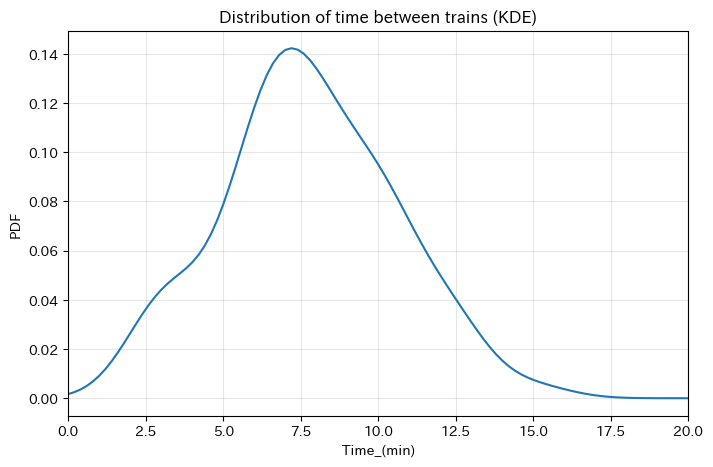

In [18]:
plt.figure(figsize=(8,5))
plt.plot(qs, pmf_z)
plt.xlabel("Time_(min)")
plt.ylabel("PDF")
plt.title("Distribution of time between trains (KDE)")
plt.xlim(0,20)
plt.grid(alpha=0.3)

print("データ件数:", n)
print(f"平均電車間隔：{zs.mean():.2f}分")
print(f"帯域幅：{bandwidth:.2f}分")